# Credit-risk modelling 

**Objectif :** prédire la probabilité qu'un client fasse défaut le mois suivant.



In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42



## 1. Chargement des données


In [ ]:
df = pd.read_excel("default of credit card clients.xls", header=1)   # nécessite xlrd

print(df.shape)
df.head()

Fichier : default_of_credit_card_clients.csv
(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Nettoyage

- Renommage : `PAY_0` → `PAY_1` (même mois que `BILL_AMT1` et `PAY_AMT1`) et la cible → `DEFAULT`.
- Suppression de `ID` : un numéro de client ne dit rien sur le risque.
- Doublons : supprimés, pour qu'un même client ne soit pas à la fois dans le train et le test.
- Codes non documentés : `EDUCATION` 0, 5, 6 → 4 (autres) ; `MARRIAGE` 0 → 3 (autres).

In [ ]:
df = df.rename(columns={"PAY_0": "PAY_1", "default payment next month": "DEFAULT"})
df = df.drop(columns="ID")

print("Valeurs manquantes :", df.isna().sum().sum())
print("Doublons supprimés :", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

print("Clients restants :", len(df))
print("Taux de défaut :", round(df["DEFAULT"].mean(), 3))

Valeurs manquantes : 0
Doublons supprimés : 35
Clients restants : 29965


Taux de défaut : 0.221


## 3. Exploration des données

### 3.1 Répartition de la cible

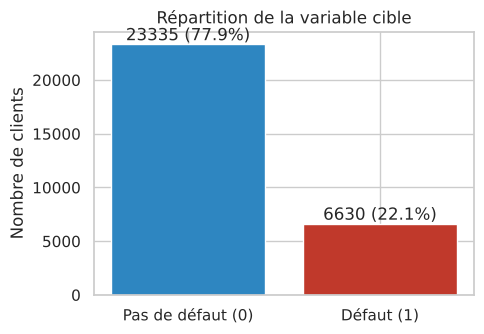

In [ ]:
counts = df["DEFAULT"].value_counts().sort_index()

plt.figure(figsize=(5, 3.5))
plt.bar(["Pas de défaut (0)", "Défaut (1)"], counts.values, color=["#239de8", "#c0392b"])
for i, v in enumerate(counts.values):
    plt.text(i, v, f"{v} ({v / len(df):.1%})", ha="center", va="bottom")
plt.ylabel("Nombre de clients")
plt.title("Répartition de la variable cible")
plt.tight_layout(); plt.show()

Les classes sont déséquilibrées : seulement 22 % des clients font défaut. Un modèle qui prédirait toujours « pas de défaut » aurait 78 % d'accuracy sans détecter un seul défaut. Il faudra donc corriger ce déséquilibre et ne pas se fier à l'accuracy.

### 3.2 Taux de défaut selon le retard de paiement en septembre (`PAY_1`)

Rappel des codes : -2 = aucune consommation, -1 = payé intégralement, 0 = paiement minimum, 1 à 8 = mois de retard.

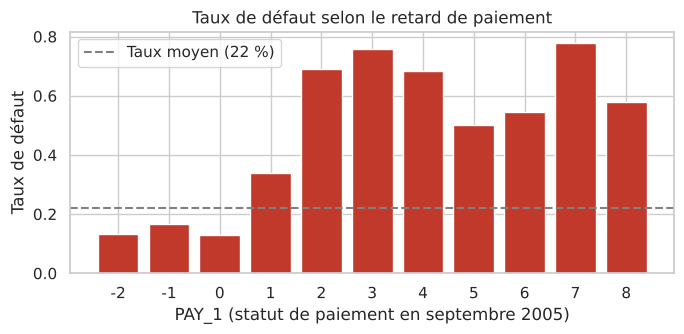

,taux_defaut,nb_clients
PAY_1,,
-2,0.132,2750
-1,0.168,5682
0,0.128,14737
1,0.340,3667
2,0.691,2666
3,0.758,322
4,0.684,76
5,0.500,26
6,0.545,11


In [ ]:
taux = df.groupby("PAY_1")["DEFAULT"].agg(taux_defaut="mean", nb_clients="size")

plt.figure(figsize=(7, 3.5))
plt.bar(taux.index.astype(str), taux["taux_defaut"], color="#c0392b")
plt.axhline(df["DEFAULT"].mean(), ls="--", c="grey", label="Taux moyen (22 %)")
plt.xlabel("PAY_1 (statut de paiement en septembre 2005)")
plt.ylabel("Taux de défaut")
plt.title("Taux de défaut selon le retard de paiement")
plt.legend(); plt.tight_layout(); plt.show()

taux.round(3)

Le retard de paiement est logiquement fortement lié au défaut : le taux de défaut est d'environ 13 % pour les clients qui paient le minimum (`PAY_1` = 0), mais monte à 34 % avec 1 mois de retard et à 69 % avec 2 mois.
### 3.3 Corrélations entre les variables

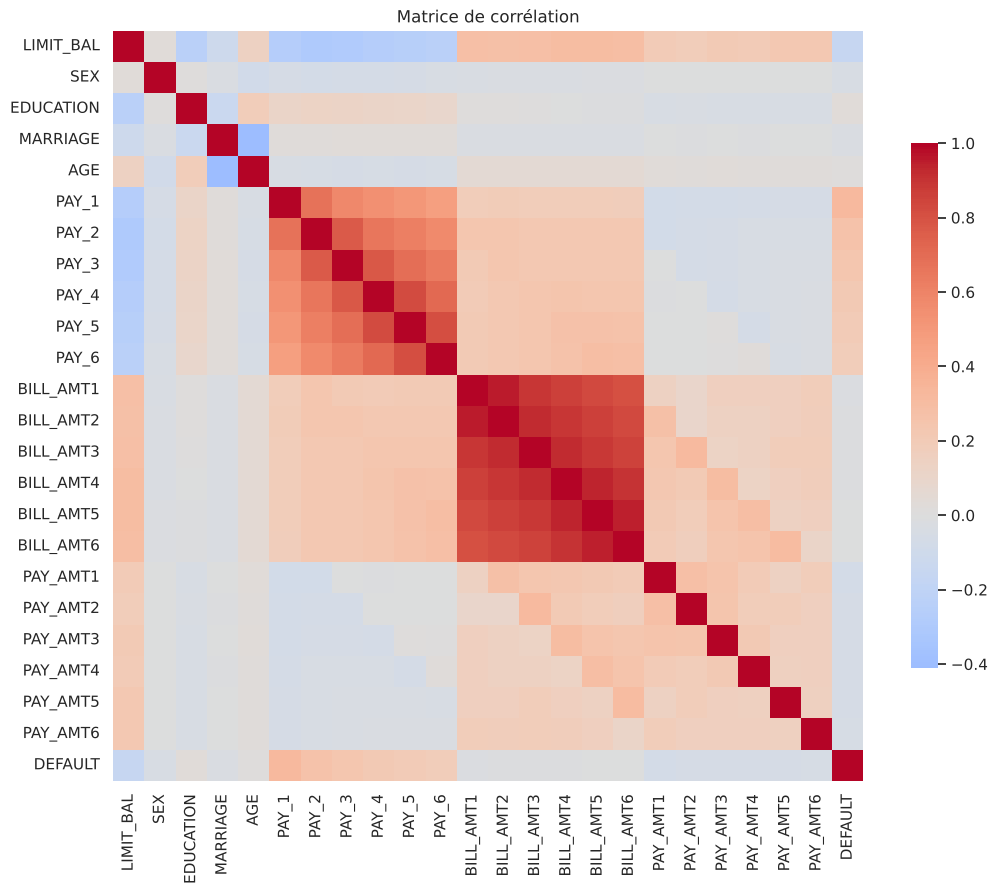

Variables les plus corrélées avec le défaut :


PAY_1        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
LIMIT_BAL   -0.154
PAY_AMT1    -0.073
Name: DEFAULT, dtype: float64

In [ ]:
corr = df.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Matrice de corrélation")
plt.tight_layout(); plt.show()

print("Variables les plus corrélées avec le défaut :")
corr["DEFAULT"].drop("DEFAULT").sort_values(key=abs, ascending=False).head(8).round(3)

Ce qu'on observe 
- Les variables les plus liées au défaut sont les retards de paiement (`PAY_1` à `PAY_6`), surtout le mois le plus récent. Un plafond élevé (`LIMIT_BAL`) va de pair avec moins de défauts.
- Les montants des relevés (`BILL_AMT`) sont presque sans lien avec le défaut, mais très corrélés entre eux (bloc rouge) : d'un mois sur l'autre, le solde change peu.
- Les variables de profil (`SEX`, `AGE`, `EDUCATION`, `MARRIAGE`) sont peu prédictives.

C'est pourquoi on va faire du feature engineering : plutôt que les montants bruts, on va construire des ratios.

## 4. Feature engineering

On crée 4 variables qui résument le comportement du client sur les 6 mois :

| Variable | Calcul | Ce qu'elle mesure |
|------|------|------|
| `UTIL_MEAN` | moyenne de `BILL_AMT` / `LIMIT_BAL` | utilisation moyenne du crédit |
| `PAY_RATIO` | `PAY_AMT1` / `BILL_AMT2` (borné entre 0 et 1) | part de la facture d'août remboursée en septembre |
| `N_MONTHS_LATE` | nombre de mois avec `PAY_x` > 0 | fréquence des retards |
| `MAX_DELAY` | plus grand `PAY_x` | gravité du pire retard |

In [ ]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payamt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
pay_cols = [f"PAY_{i}" for i in range(1, 7)]

df["UTIL_MEAN"] = df[bill_cols].mean(axis=1) / df["LIMIT_BAL"]

# Si la facture est nulle ou négative, il n'y a rien à rembourser : ratio = 1
df["PAY_RATIO"] = np.where(df["BILL_AMT2"] > 0, df["PAY_AMT1"] / df["BILL_AMT2"], 1)
df["PAY_RATIO"] = df["PAY_RATIO"].clip(0, 1)

df["N_MONTHS_LATE"] = (df[pay_cols] > 0).sum(axis=1)
df["MAX_DELAY"] = df[pay_cols].max(axis=1).clip(lower=0)

# Lien des nouvelles variables avec le défaut
df[["UTIL_MEAN", "PAY_RATIO", "N_MONTHS_LATE", "MAX_DELAY", "PAY_1", "DEFAULT"]].corr()["DEFAULT"].round(3)

UTIL_MEAN        0.115
PAY_RATIO       -0.104
N_MONTHS_LATE    0.398
MAX_DELAY        0.370
PAY_1            0.325
DEFAULT          1.000
Name: DEFAULT, dtype: float64

## 5. Séparation train / test

80 % pour l'entraînement, 20 % pour le test. Le split est stratifié (`stratify=y`) : le train et le test gardent la même proportion de défauts (22 %).
Le test ne sera utilisé qu'à la toute fin.

In [ ]:
X = df.drop(columns="DEFAULT")
y = df["DEFAULT"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train :", X_train.shape, "| taux de défaut :", round(y_train.mean(), 3))
print("Test  :", X_test.shape, "| taux de défaut :", round(y_test.mean(), 3))

Train : (23972, 27) | taux de défaut : 0.221


Test  : (5993, 27) | taux de défaut : 0.221


## 6. Encodage et mise à l'échelle

1. <u>One-hot encoding</u> de `SEX`, `EDUCATION`, `MARRIAGE` : ce sont des étiquettes, pas des grandeurs.
2. <u>Transformation log</u> de `LIMIT_BAL` et des `PAY_AMT` : ces montants sont très asymétriques (quelques valeurs énormes). Les `BILL_AMT` peuvent être négatifs, donc on ne leur applique pas le log.
3. <u>Standardisation</u> (moyenne 0, écart-type 1) : indispensable pour la régression logistique régularisée.

⚠️ Le `StandardScaler` est ajusté sur le train uniquement, puis appliqué au test, pour éviter toute Data leakage.

In [ ]:
def prepare(X):
    X = pd.get_dummies(X, columns=["SEX", "EDUCATION", "MARRIAGE"], drop_first=True, dtype=int)
    for col in ["LIMIT_BAL"] + payamt_cols:
        X[col] = np.log1p(X[col])
    return X

X_train_p = prepare(X_train)
X_test_p = prepare(X_test).reindex(columns=X_train_p.columns, fill_value=0)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_p)   # fit sur le train
X_test_s = scaler.transform(X_test_p)         # simple application sur le test

print("Nombre de variables après encodage :", X_train_s.shape[1])

Nombre de variables après encodage : 30


Fctn pour calculer toutes les métriques d'un coup.

In [ ]:
def evaluate(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"Modèle": name, "Seuil": threshold,
            "ROC-AUC": roc_auc_score(y_true, proba),
            "F1": f1_score(y_true, pred),
            "Précision": precision_score(y_true, pred),
            "Rappel": recall_score(y_true, pred),
            "Accuracy": accuracy_score(y_true, pred)}

results = []

## 7. Régression logistique

### 7.1 Baseline brute

Régression logistique par défaut, sans correction du déséquilibre, seuil 0,5.

In [ ]:
lr_base = LogisticRegression(max_iter=1000)
lr_base.fit(X_train_s, y_train)
p_base = lr_base.predict_proba(X_test_s)[:, 1]

results.append(evaluate("LR baseline", y_test, p_base))
pd.DataFrame(results).round(3)

,Modèle,Seuil,ROC-AUC,F1,Précision,Rappel,Accuracy
0,LR baseline,0.5,0.758,0.414,0.655,0.303,0.81


L'accuracy semble ok, mais le rappel est faible : le modèle rate la majorité des défauts, car il privilégie la classe majoritaire.

### 7.2 Correction du déséquilibre : `class_weight="balanced"`

Avec 22 % de défauts, chaque erreur sur un défaut reçoit un poids environ 3,5 fois plus élevé dans la fonction de perte. Le modèle est donc davantage pénalisé quand il rate un défaut.

In [ ]:
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_bal.fit(X_train_s, y_train)
p_bal = lr_bal.predict_proba(X_test_s)[:, 1]

results.append(evaluate("LR balanced", y_test, p_bal))
pd.DataFrame(results).round(3)

,Modèle,Seuil,ROC-AUC,F1,Précision,Rappel,Accuracy
0,LR baseline,0.5,0.758,0.414,0.655,0.303,0.81
1,LR balanced,0.5,0.761,0.512,0.438,0.617,0.74


## 8. Choix du seuil de décision

Le seuil de 0,5 n'est pas unique. ON peut l'optimiser en cherchant celui qui va maximiser F1.

Il est possibl de faire une validation croisée à 5 plis sur le train avec `cross_val_predict` : le train est coupé en 5 morceaux, et chaque client reçoit une probabilité calculée par un modèle entraîné sur les 4 autres morceaux, donc qui ne l'a pas vu.

Seuil retenu : 0.62


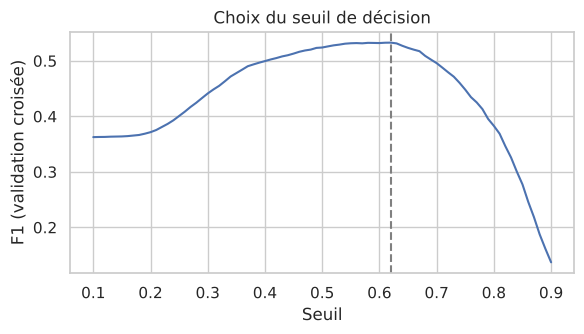

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
best_lr = lr_bal
p_train_cv = cross_val_predict(best_lr, X_train_s, y_train, cv=cv, method="predict_proba")[:, 1]

seuils = np.arange(0.10, 0.91, 0.01)
f1s = [f1_score(y_train, (p_train_cv >= s).astype(int)) for s in seuils]
best_seuil = round(float(seuils[np.argmax(f1s)]), 2)
print("Seuil retenu :", best_seuil)

plt.figure(figsize=(6, 3.5))
plt.plot(seuils, f1s)
plt.axvline(best_seuil, ls="--", c="grey")
plt.xlabel("Seuil"); plt.ylabel("F1 (validation croisée)")
plt.title("Choix du seuil de décision")
plt.tight_layout(); plt.show()

## 9. Évaluation finale sur le test

In [ ]:
p_best = best_lr.predict_proba(X_test_s)[:, 1]
results.append(evaluate("LR balanced + seuil optimisé", y_test, p_best, best_seuil))

res = pd.DataFrame(results).set_index("Modèle").round(3)
res

,Seuil,ROC-AUC,F1,Précision,Rappel,Accuracy
Modèle,,,,,,
LR baseline,0.50,0.758,0.414,0.655,0.303,0.810
LR balanced,0.50,0.761,0.512,0.438,0.617,0.740
LR balanced + seuil optimisé,0.62,0.761,0.526,0.514,0.540,0.785


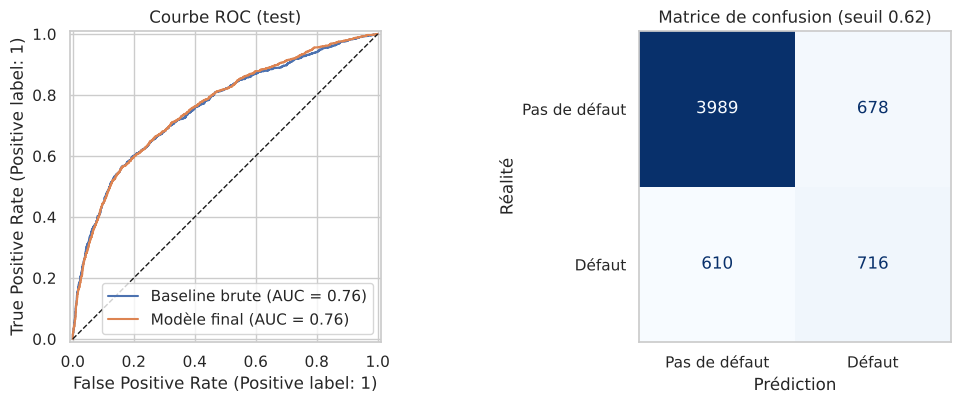

Défauts détectés : 716 sur 1326 (54%)


Défauts manqués : 610 | Fausses alertes : 678


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

RocCurveDisplay.from_predictions(y_test, p_base, name="Baseline brute", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, p_best, name="Modèle final", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("Courbe ROC (test)")

cm = confusion_matrix(y_test, (p_best >= best_seuil).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["Pas de défaut", "Défaut"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_xlabel("Prédiction"); axes[1].set_ylabel("Réalité"); axes[1].grid(False)
axes[1].set_title(f"Matrice de confusion (seuil {best_seuil})")

plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Défauts détectés : {tp} sur {tp + fn} ({tp / (tp + fn):.0%})")
print(f"Défauts manqués : {fn} | Fausses alertes : {fp}")

## 10. Interprétation des coefficients

Les variables sont standardisées : quand une variable augmente d'un écart-type, la cote du défaut est multipliée par $e^{\beta}$ (cours 4).
- coefficient positif (rouge) → augmente le risque ;
- coefficient négatif (vert) → réduit le risque.

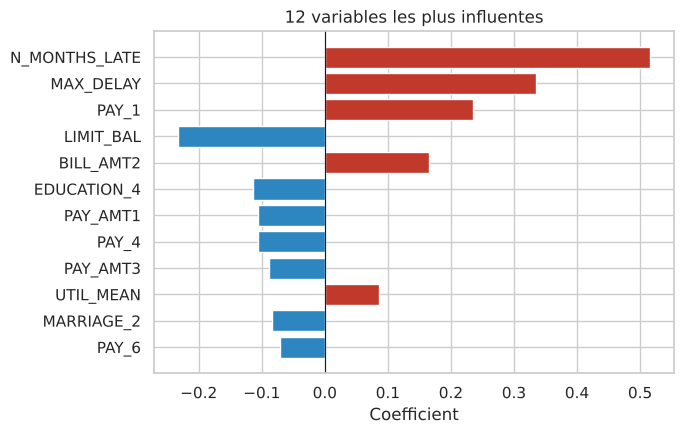

,variable,coef,odds_ratio
0,N_MONTHS_LATE,0.516,1.676
1,MAX_DELAY,0.335,1.398
2,PAY_1,0.234,1.264
3,LIMIT_BAL,-0.233,0.792
4,BILL_AMT2,0.166,1.181
5,EDUCATION_4,-0.114,0.893
6,PAY_AMT1,-0.107,0.899
7,PAY_4,-0.105,0.900
8,PAY_AMT3,-0.089,0.915
9,UTIL_MEAN,0.087,1.091


In [ ]:
coefs = pd.DataFrame({"variable": X_train_p.columns, "coef": best_lr.coef_[0]})
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs = coefs.reindex(coefs["coef"].abs().sort_values(ascending=False).index)

top = coefs.head(12).iloc[::-1]
plt.figure(figsize=(7, 4.5))
plt.barh(top["variable"], top["coef"], color=np.where(top["coef"] > 0, "#d71a30", "#2e86c1"))
plt.axvline(0, c="k", lw=0.8)
plt.xlabel("Coefficient")
plt.title("12 variables les plus influentes")
plt.tight_layout(); plt.show()

coefs.head(12).round(3).reset_index(drop=True)

Lecture : les variables de retard de paiement (`N_MONTHS_LATE`, `MAX_DELAY`, `PAY_1`) augmentent le plus le risque. Un plafond élevé (`LIMIT_BAL`) et des remboursements importants (`PAY_AMT`) le réduisent. Le feature engineering est plus qu'utile

## Résultats finaux

Ces scores servent de base line : les autres modèles devront faire mieux.

In [ ]:
pd.DataFrame(results).set_index("Modèle").round(3)

,Seuil,ROC-AUC,F1,Précision,Rappel,Accuracy
Modèle,,,,,,
LR baseline,0.50,0.758,0.414,0.655,0.303,0.810
LR balanced,0.50,0.761,0.512,0.438,0.617,0.740
LR balanced + seuil optimisé,0.62,0.761,0.526,0.514,0.540,0.785
